# 2. Characterising eccentricity detectability

In [1]:
import numpy as np

import sys
sys.path.append("../emri_tools")
from gw_signal import get_frequency_evolution
from utils import PSD
from file_handling import load_hdf5

import matplotlib.pyplot as plt
from seaborn import color_palette
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "text.latex.preamble": r"\usepackage{amsfonts}",
    "font.size": 17,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "legend.frameon": False
})

In [2]:
tdi_flag = False
psd = PSD(tdi_flag)

Using LISA PSD


## 2.1. Configuration

In [3]:
# Fiducial system's parameters
m1, m2 = 4e6, 10.0
a, Tpl = 0, 0.9
xI = 1.0

DEFAULT_INJECTION = {
    'm1': m1, 
    'm2': m2,
    'a': a,  
    'Tpl': Tpl,
    'ef': 0, 
}

# Short-time Fourier Transform (SFT) and observation parameters
T_SFT = 172800      # SFT duration [seconds], corresponding to 2 days (default is 5e4)
T_DATA = 1.0        # Total observation time [years]
DELTA_T = 5.0       # Time step [seconds]

## 2.2. Maximum likelihood estimations (eccentric and circular hypothesis)

In [4]:
filenames = ["../results/2_lambda_ef_20_mode.h5",
             "../results/2_lambda_ef_dom_mode.h5",
             "../results/2_lambda_ef_50_thr.h5",
             "../results/2_lambda_ef_75_thr.h5",]

labels = ["(2,0) Mode", "Dominant Mode", r"50\% SNR Modes", r"75\% SNR Modes"]
cpal = ["#f9c74f", "#ed7d53", "#8088ad", "#b73779"]
style = ["-", "--", (0, (1, 1)), "-."]

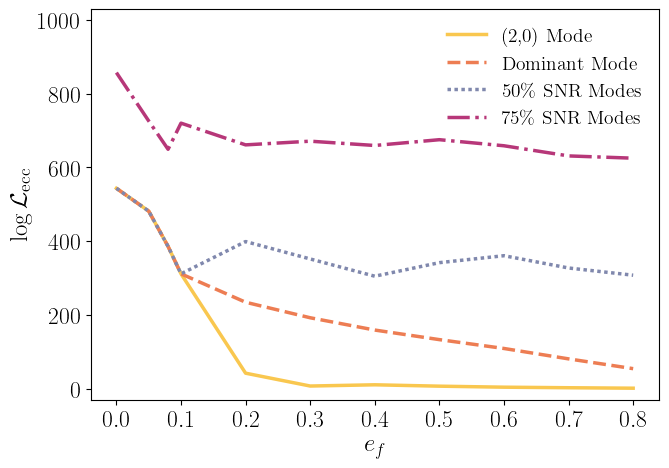

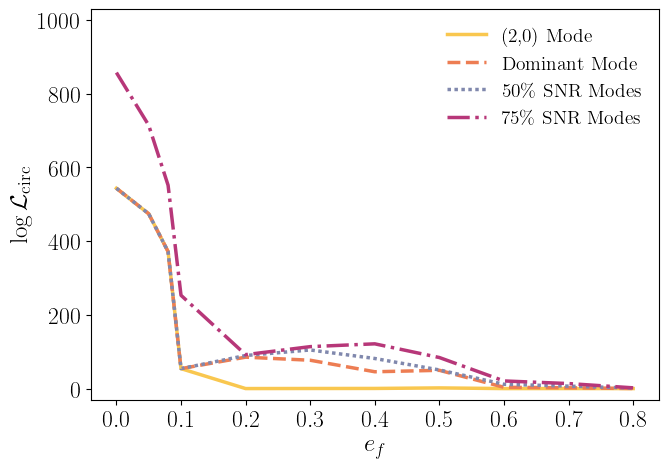

In [5]:
fig_ecc, ax_ecc = plt.subplots(figsize=(7,5))
fig_circ, ax_circ = plt.subplots(figsize=(7,5))

for i, filename in enumerate(filenames):
    
    df = load_hdf5(filename)
    
    vals_ef = df["ef_inj"].values
    vals_logL_ecc = df["logL_ecc"].values
    vals_logL_circ = df["logL_circ"].values

    ax_ecc.plot(vals_ef, vals_logL_ecc, linestyle=style[i], lw=2.5, label=labels[i], c=cpal[i])
    ax_circ.plot(vals_ef, vals_logL_circ, linestyle=style[i], lw=2.5, label=labels[i], c=cpal[i])

ax_ecc.set_xticks(np.arange(0, 0.81, 0.1))
ax_ecc.set_ylim([-30, 1030])
ax_ecc.set_xlabel(r"$e_f$")
ax_ecc.set_ylabel(r"$\log \mathcal L_{\rm ecc}$")
ax_ecc.legend(loc='upper right', fontsize=14)
fig_ecc.tight_layout()

ax_circ.set_xticks(np.arange(0, 0.81, 0.1))
ax_circ.set_ylim([-30, 1030])
ax_circ.set_xlabel(r"$e_f$")
ax_circ.set_ylabel(r"$\log \mathcal L_{\rm circ}$")
ax_circ.legend(loc='upper right', fontsize=14)
fig_circ.tight_layout()

#fig_ecc.savefig("../figures/2_logL_eccentric.pdf", bbox_inches='tight')
#fig_circ.savefig("../figures/2_logL_circular.pdf", bbox_inches='tight')

plt.show()

## 2.3. Relative biases (eccentric and circular hypothesis)

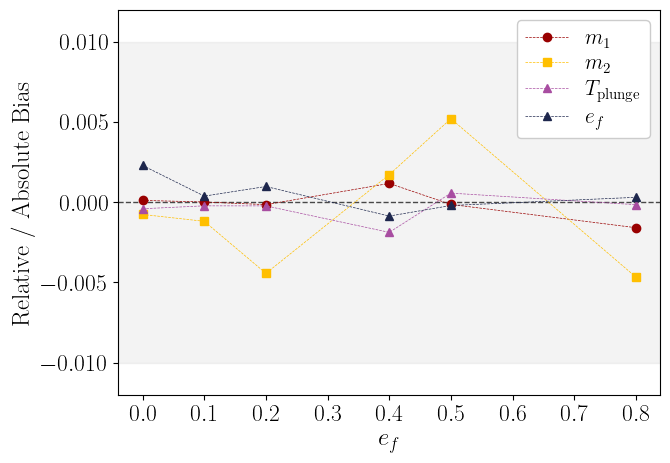

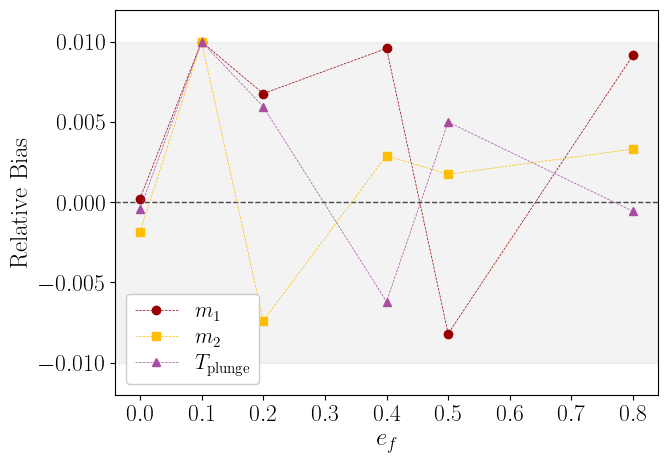

In [6]:
filepath = "../results/2_lambda_ef_75_thr.h5"
df = load_hdf5(filepath)

vals_ef = df["ef_inj"].values
mask = np.isin(vals_ef, np.arange(0, 0.81, 0.1))
vals_ef = vals_ef[mask]

vals_h0_m1 = df["h0_m1"].values[mask]
vals_h0_m2 = df["h0_m2"].values[mask]
vals_h0_a = df["h0_a"].values[mask]
vals_h0_Tpl = df["h0_Tpl"].values[mask]
vals_h1_m1 = df["h1_m1"].values[mask]
vals_h1_m2 = df["h1_m2"].values[mask]
vals_h1_a = df["h1_a"].values[mask]
vals_h1_Tpl = df["h1_Tpl"].values[mask]
vals_h1_ef = df["h1_ef"].values[mask]

cpal_biases = ["#990000", "#ffbf00", "#a84da1", "#1e274d"]

### Plot of the biases relative to the eccentric hypothesis

plt.figure(figsize=(7,5))
plt.axhline(0, color="black", lw=1, ls="--", alpha=0.7)
plt.axhspan(-0.01, 0.01, color="gray", alpha=0.09)
plt.plot(vals_ef, (10**vals_h1_m1 - m1) / m1, "--", marker="o", color=cpal_biases[0], label=r"$m_1$", lw=0.5)
plt.plot(vals_ef, (vals_h1_m2 - m2) / m2, "--", marker="s", color=cpal_biases[1], label=r"$m_2$", lw=0.5)
plt.plot(vals_ef, (vals_h1_Tpl - Tpl) / Tpl, "--", marker="^", color=cpal_biases[2], label=r"$T_{\rm plunge}$", lw=0.5)
plt.plot(vals_ef, vals_h1_ef - vals_ef, "--", marker="^", color=cpal_biases[3], label=r"$e_f$", lw=0.5)

plt.xticks(np.arange(0, 0.81, 0.1))
plt.ylim([-0.012, 0.012])
plt.xlabel(r"$e_f$")
plt.ylabel("Relative / Absolute Bias")
plt.legend(loc="upper right", frameon=True, framealpha=1, ncols=1, labelspacing=0.3, columnspacing=0.9, fontsize=15.5)
#plt.savefig('../figures/2_bias_eccentric.pdf', bbox_inches='tight')
plt.show()

### Plot of the biases relative to the circular hypothesis

plt.figure(figsize=(7,5))
plt.axhline(0, color="black", lw=1, ls="--", alpha=0.7)
plt.axhspan(-0.01, 0.01, color="gray", alpha=0.09)
plt.plot(vals_ef, (10**vals_h0_m1 - m1) / m1, "--", marker="o", color=cpal_biases[0], label=r"$m_1$", lw=0.5)
plt.plot(vals_ef, (vals_h0_m2 - m2) / m2, "--", marker="s", color=cpal_biases[1], label=r"$m_2$", lw=0.5)
plt.plot(vals_ef, (vals_h0_Tpl - Tpl) / Tpl, "--", marker="^", color=cpal_biases[2], label=r"$T_{\rm plunge}$", lw=0.5)

plt.xticks(np.arange(0, 0.81, 0.1))
plt.ylim([-0.012, 0.012])
plt.xlabel(r"$e_f$")
plt.ylabel("Relative Bias")
plt.legend(loc="lower left", frameon=True, framealpha=1, ncols=1, labelspacing=0.3, columnspacing=0.9, fontsize=15.5)
#plt.savefig('../figures/2_bias_circular.pdf', bbox_inches='tight')
plt.show()

## 2.4. Eccentricity detection statistic

In [7]:
true_params = np.array([m1, m2, a, Tpl, 0, xI])
vals_ef_beg = np.linspace(0, 0.1, 10)
scaling_beg = np.zeros(len(vals_ef_beg))

for i, ef in enumerate(vals_ef_beg):
    true_params[4] = ef
    t_alpha, true_phi_f_fdot_fddot, amp_alpha = get_frequency_evolution(true_params, T_DATA, T_SFT, DELTA_T)
    f_phi_alpha = true_phi_f_fdot_fddot[1][0]
    K_1 = np.sum(amp_alpha**2 / psd(2 * f_phi_alpha))
    scaling_beg[i] = K_1 * ef**4

Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU
Using response generator
Waveform generated on CPU


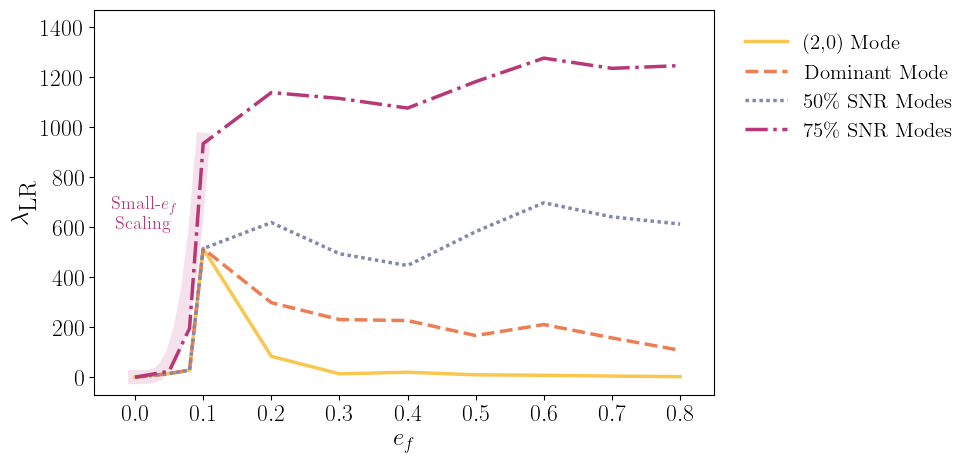

In [8]:
plt.figure(figsize=(8, 5))

scale = 950 / scaling_beg[-1]
scaling_beg_plot = scaling_beg * scale
plt.plot(vals_ef_beg, scaling_beg_plot, linestyle="-", lw=10, c="#b73779", alpha=0.15)
plt.text(0.011, 650, "Small-$e_f$ \n Scaling", c="#b73779", fontsize=13, ha='center', va='center')

for i, filename in enumerate(filenames):
    
    df = load_hdf5(filename)
    
    vals_ef = df["ef_inj"].values
    vals_lambda_LR = df["lambda_LR"].values

    plt.plot(vals_ef, vals_lambda_LR, linestyle=style[i], lw=2.5, label=labels[i], c=cpal[i])

plt.xlim([-0.06, 0.85])
plt.xticks(np.arange(0, 0.81, 0.1))
plt.ylim([-70, 1470])
plt.xlabel(r"$e_f$")
plt.ylabel(r"$\lambda_\textrm{LR}$")
plt.legend(loc='center left', bbox_to_anchor=(1.02, 0.8), fontsize=15, frameon=False)
#plt.savefig('../figures/2_det_stats_mode_selection.pdf', bbox_inches='tight')
plt.show()

## 2.5. Impact of varying the SFT window

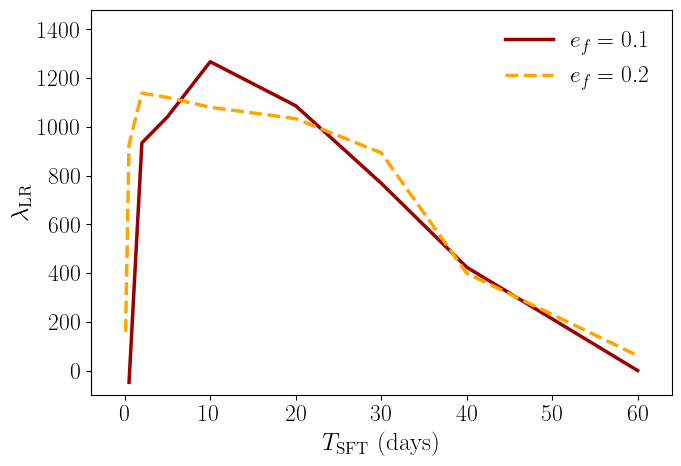

In [9]:
filenames = ["../results/2_lambda_Tsft_ef_0.1.h5",
             "../results/2_lambda_Tsft_ef_0.2.h5"]

labels = ["$e_f=0.1$", "$e_f=0.2$"]
colors = ["#990000", "orange"]
style = ["-", "--"]

plt.figure(figsize=(7.5,5))

for filename, l, c, s in zip(filenames, labels, colors, style):
    
    df = load_hdf5(filename)
    
    vals_T_SFT = df["t_sft"].values
    vals_lambda_LR = df["lambda_LR"].values
    
    idx = np.argsort(vals_T_SFT)
    vals_T_SFT = vals_T_SFT[idx]
    vals_lambda_LR = vals_lambda_LR[idx]
    
    plt.plot(vals_T_SFT / 86400, vals_lambda_LR, s, lw=2.5, label=l, c=c)

plt.xlim([-4, 64])
plt.ylim([-100, 1480])
plt.xlabel(r"$T_{\rm SFT}$ (days)")
plt.ylabel(r"$\lambda_{\rm LR}$")
plt.legend(frameon=False)
#plt.savefig('../figures/2_det_stats_Tsft.pdf', bbox_inches='tight')
plt.show()